# Hybrid φ on the test networks: threshold, budget, robustness

**Internship at CoMuNe Lab** · Riccardo Corte

The hybrid `φ` (screened nodes at `φ = 1`, all the others at the same `φ`) is defined and checked in
notebook 03. Here it is applied to the three test networks with the three screening protocols. The functions
are imported from `mp.py`, which collects the code of notebook 03.

Structure: 0. setup and networks; 1. critical threshold for each protocol (1.1 `φ_c`, 1.2 critical budget
`f*`, 1.3 total robustness, 1.4 check against Monte Carlo); 2. curves `S(φ)` for each protocol (2.1 thresholds on the curves at fixed `f`, 2.2 the network below and above `φ_c`); conclusions.

## 0. Setup

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

from mp import (message_passing, mc_1run, curve_mc, scarto_quadratico_medio, matrice_G, lambda_max,
                estrai_protetti, phi_ibrido, phi_efficace, matrice_M, lambda_zero, soglia_bisezione,
                budget_critico, lcc_protetti, num_estrazioni, griglia_phi, scarto_quadratico_integrale,
                struttura_mp, message_passing_veloce, curva_mp, struttura_mc, mc_1run_veloce)

rng = np.random.default_rng(0)

protocolli = ["random", "degree", "betweenness"]


### 0.1 Networks

The three test networks of notebook 03, section 1 (same parameters and seeds).

In [2]:
# --- parameters ---
N_big = 1000        # number of nodes of each graph
n_blocchi = 4       # communities of the block model, N_big / n_blocchi nodes each
k_dentro = 2.8      # mean number of links of a node inside its own community
k_fuori = 0.2       # mean number of links of a node towards the other communities
k_er = 3            # mean degree of the Erdos-Renyi graph
m_ba = 3            # links brought by each new node in the Barabasi-Albert graph

# link probabilities of the block model: with n nodes per community, a node has n - 1 possible
# partners inside and N_big - n outside, so p = (mean number of links) / (possible partners)
n_com = N_big // n_blocchi
p_dentro = k_dentro / (n_com - 1)
p_fuori = k_fuori / (N_big - n_com)

# --- the three graphs ---
grafi = {
    "communities": nx.stochastic_block_model(
        [N_big // n_blocchi] * n_blocchi,
        [[p_dentro if a == b else p_fuori for b in range(n_blocchi)] for a in range(n_blocchi)],
        seed=1),
    "Erdos-Renyi": nx.gnp_random_graph(N_big, k_er / (N_big - 1), seed=1),
    "Barabasi-Albert": nx.barabasi_albert_graph(N_big, m_ba, seed=1),
}

# --- check: what we have built ---
for nome, g in grafi.items():
    gradi = [d for _, d in g.degree]
    lcc = max(nx.connected_components(g), key=len)
    print(nome)
    print("  nodes:", g.number_of_nodes(), " links:", g.number_of_edges())
    print("  mean degree:", np.mean(gradi), " min:", min(gradi), " max:", max(gradi))
    print("  connected:", nx.is_connected(g), " LCC/N with no removal:", len(lcc) / N_big)

# links between different communities (the block of each node is in the attribute "block")
g = grafi["communities"]
tra = sum(1 for u, v in g.edges() if g.nodes[u]["block"] != g.nodes[v]["block"])
print("communities: links between communities", tra, "out of", g.number_of_edges())


communities
  nodes: 1000  links: 1529
  mean degree: 3.058  min: 0  max: 9
  connected: False  LCC/N with no removal: 0.943
Erdos-Renyi
  nodes: 1000  links: 1486
  mean degree: 2.972  min: 0  max: 9
  connected: False  LCC/N with no removal: 0.934
Barabasi-Albert
  nodes: 1000  links: 2991
  mean degree: 5.982  min: 1  max: 91
  connected: True  LCC/N with no removal: 1.0
communities: links between communities 94 out of 1529


## 1. Critical threshold for each protocol

### 1.1 φ_c for each protocol

For each network, protocol and fraction `f` of screened nodes, `φ_c` from the bisection of notebook 03, section 4.3, for
`f` from 0 to 30 screened nodes out of 1000, one node at a time, plus `f = 0.05, 0.10, 0.25` as a reference for
large screening. Number of draws of the screened nodes from `num_estrazioni` (`mp.py`): one draw when the
protocol always picks the same set of nodes (degree and betweenness without ties at the cut), otherwise
`round(30/n) + 10`, with `n` the number of screened nodes (random, and degree or betweenness with ties at the cut). Small values of `f` are included for Barabási-Albert, where the hubs alone percolate
already at `f = 0.005` (notebook 03, section 4.2).

In [3]:
frazioni_44 = [n / 1000 for n in range(31)] + [0.05, 0.10, 0.25]   # 0 to 30 screened nodes out of 1000, then large f

ESEGUI_RUN_44 = False     # True: run again (about 15 minutes); False: read the results saved in soglie_protocolli.csv

if ESEGUI_RUN_44:
    righe = []
    for nome, g in grafi.items():
        G_mat, messaggi = matrice_G(g)       # once per network
        betw = nx.betweenness_centrality(g)
        for protocollo in protocolli:
            for frazione in frazioni_44:
                for e in range(num_estrazioni(g, frazione, protocollo, betw)):
                    protetti = estrai_protetti(g, frazione, protocollo, rng, betw)
                    righe.append({"network": nome, "protocol": protocollo, "f": frazione, "draw": e,
                                  "phi_c": soglia_bisezione(g, G_mat, messaggi, protetti)})
    soglie_prot = pd.DataFrame(righe)
    soglie_prot.to_csv("risultati/04/soglie_protocolli.csv", index=False)     # saved, so that the run is not needed again
else:
    soglie_prot = pd.read_csv("risultati/04/soglie_protocolli.csv")

In [4]:
# mean and standard deviation of phi_c over the draws, and number of draws: one row per (network, protocol);
# the table shows only some values of f, the plot below has all of them
sintesi_44 = soglie_prot.groupby(["network", "protocol", "f"], sort=False)["phi_c"].agg(["mean", "std", "count"])
f_tabella = [0.0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.10, 0.25]
sintesi_44["mean"].unstack("f")[f_tabella].round(4)

f                             0.000   0.001   0.003   0.010   0.030   0.050  \
network         protocol                                                      
communities     random       0.3259  0.3252  0.3228  0.3194  0.2995  0.2796   
                degree       0.3259  0.3192  0.3064  0.2438  0.1843  0.1226   
                betweenness  0.3259  0.3214  0.3080  0.2839  0.1782  0.1038   
Erdos-Renyi     random       0.3412  0.3407  0.3392  0.3343  0.3249  0.3084   
                degree       0.3412  0.3345  0.3171  0.2944  0.2416  0.1984   
                betweenness  0.3412  0.3336  0.3144  0.2813  0.2036  0.1015   
Barabasi-Albert random       0.0930  0.0916  0.0915  0.0848  0.0750  0.0606   
                degree       0.0930  0.0545  0.0000  0.0000  0.0000  0.0000   
                betweenness  0.0930  0.0545  0.0000  0.0000  0.0000  0.0000   

f                             0.100   0.250  
network         protocol                     
communities     random       0.2402  0.0848  
                degree       0.0000  0.0000  
                betweenness  0.0000  0.0000  
Erdos-Renyi     random       0.2700  0.1478  
                degree       0.0697  0.0000  
                betweenness  0.0000  0.0000  
Barabasi-Albert random       0.0237  0.0000  
                degree       0.0000  0.0000  
                betweenness  0.0000  0.0000

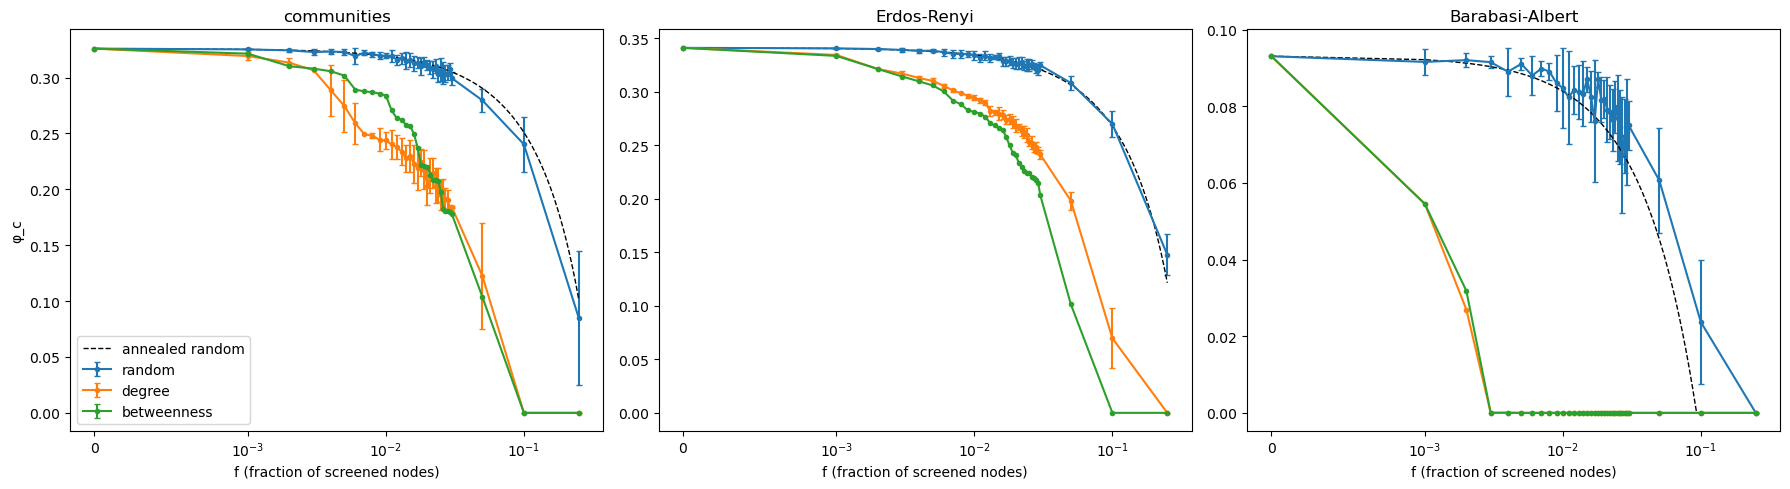

In [5]:
# phi_c against f, one panel per network, one line per protocol;
# dashed: annealed random screening, phi_eff = 1/lambda_max, i.e. phi_c = (1/lambda_max - f)/(1 - f), cut at 0
fig, assi = plt.subplots(1, len(grafi), figsize=(18, 5))
for ax, (nome, g) in zip(assi, grafi.items()):
    for protocollo in protocolli:
        t = sintesi_44.loc[(nome, protocollo)]
        ax.errorbar(t.index, t["mean"], yerr=t["std"], fmt="o-", ms=3, capsize=2, label=protocollo)
    inv_lam = 1 / lambda_max(matrice_G(g)[0])
    f_fine = np.linspace(0, max(frazioni_44), 500)
    ax.plot(f_fine, np.maximum(0, (inv_lam - f_fine) / (1 - f_fine)), "k--", lw=1, label="annealed random")
    ax.set_xscale("symlog", linthresh=0.001)      # linear below 0.001, logarithmic above: shows f = 0 and the small f
    ax.set_title(nome)
    ax.set_xlabel("f (fraction of screened nodes)")
assi[0].set_ylabel("φ_c")
assi[0].legend()
plt.tight_layout()
plt.show()


**Comment on section 1.1.** As the fraction of screened nodes grows, `φ_c` goes from the value of the intact
network down to 0, on all the networks and for all the protocols. The dashed curve is the annealed random
reference of notebook 03, section 4.3.

**Protocols.** Betweenness is the best protocol, or as good as degree, everywhere. On the network with
communities degree and betweenness behave about the same and bring `φ_c` to 0 at `f = 0.1`: with 10% of the
nodes screened the network never loses its giant component. On Erdős-Rényi degree is less effective than
betweenness (`f = 0.05`: 0.198 against 0.102; `f = 0.1`: 0.070 against 0). On Barabási-Albert degree and
betweenness give `φ_c = 0` already at `f = 0.005`: a very small fraction of screened hubs keeps the giant
component.

**Random screening and its error bars.** The bars are the standard deviation of `φ_c` over the 10 draws: they say
how much the threshold changes from one set of screened nodes to another, a real property of the quenched case,
not an error of the method. Example: communities, `f = 0.25`, the 10 draws give 0, 0.108, 0.140, 0.144, 0.117, 0, 0,
0.105, 0.115, 0.119 (mean 0.085, standard deviation 0.060): in three draws the 250 screened nodes happened
to contain enough cycles to percolate alone. More draws do not shrink this spread by construction, but they
measure it better: with 10 draws even the fraction of such cases is poorly known (3 out of 10 is compatible with
a true probability from less than 10% to about two thirds), so both the mean and the width of the bar are rough
estimates. The error on the mean, standard deviation / √10 (0.019 here), does shrink with more draws.

**Quenched against annealed.** For small `f` the random protocol follows the annealed curve. For larger `f` they
separate by more than the error on the mean: Barabási-Albert, `f = 0.05`: 0.061 against 0.045; `f = 0.1`: 0.024
against 0; Erdős-Rényi, `f = 0.25`: 0.148 against 0.122. The
annealed formula treats every node as present with probability `φ_eff` independently of the others, and cannot
see that in a given draw the screened nodes may already form a structure that percolates alone (as in the three
draws at 0 above). This is a plausible reading, not yet checked draw by draw with `λ(0)`.

**What this section shows.** It measures how different the protocols are and how `φ_c` depends on `f`. It shows
that the random protocol is consistent with the annealed theory for small `f`; it does not by itself show that
`φ_c` is accurate on the real network: that comes from the checks of notebook 03, section 4.3 and from the comparison with
Monte Carlo of section 1.4.

### 1.2 Critical budget f*

**Question.** How many nodes do we have to screen so that the network never loses its giant component, for any
`φ`? This is the critical budget `f*`: the smallest fraction of screened nodes for which `φ_c = 0`. From
notebook 03, section 4.2, `φ_c = 0` means that the screened nodes alone percolate, `λ(0) ≥ 1`, where `λ(0)` is the largest
eigenvalue of `G` built on the subgraph of the screened nodes (`lambda_zero`).

**How it is computed.** We work with the number of screened nodes `k` instead of the fraction: `k = f N`
(with `N = 1000`, `f = 0.005` means `k = 5`), so `f* = k*/N`. Each protocol gives a ranking of all the nodes
(`estrai_protetti` with `f = 1`): by degree, by betweenness, or a random order. Screening `k` nodes means taking
the first `k` of the ranking. Going from `k` to `k + 1` adds one node and removes none, so the subgraph of the
screened nodes only gains nodes and links, and `λ(0)` can only grow with `k` (same argument as notebook 03, section 4.2:
entries of `M` go from 0 to 1, none goes down). So there is a single smallest `k*` with `λ(0) ≥ 1`, and it is
found by bisection on `k` between 0 and `N`, as in notebook 03, section 4.3 but on an integer. For the random protocol each
draw is a new random order, and `f*` is averaged over 10 draws; for degree the draws differ only in the ties.

In [6]:
def budget_critico(g, ordine):
    """Smallest number of nodes, taken from the start of the list `ordine`, that percolate alone at phi = 0
    (lambda(0) >= 1). Returns nan if even all the nodes do not percolate."""
    if lambda_zero(g, ordine) < 1:
        return np.nan
    basso, alto = 0, len(ordine)        # lambda(0) < 1 with the first `basso` nodes, >= 1 with the first `alto`
    while alto - basso > 1:
        medio = (basso + alto) // 2
        if lambda_zero(g, ordine[:medio]) >= 1:
            alto = medio
        else:
            basso = medio
    return alto


In [7]:
num_estrazioni_45 = 10     # draws of the order of the nodes (ties, random)

righe = []
for nome, g in grafi.items():
    betw = nx.betweenness_centrality(g)
    for protocollo in protocolli:
        for e in range(num_estrazioni_45):
            ordine = estrai_protetti(g, 1.0, protocollo, rng, betw)      # all the nodes, in the order of the protocol
            k = budget_critico(g, ordine)
            righe.append({"network": nome, "protocol": protocollo, "draw": e, "f*": k / g.number_of_nodes()})
budget = pd.DataFrame(righe)
sintesi_45 = budget.groupby(["network", "protocol"], sort=False)["f*"].agg(["mean", "std"])
sintesi_45.round(4)


mean     std
network         protocol                   
communities     random       0.3577  0.0575
                degree       0.1176  0.0162
                betweenness  0.0790  0.0000
Erdos-Renyi     random       0.3885  0.0306
                degree       0.1284  0.0181
                betweenness  0.0790  0.0000
Barabasi-Albert random       0.1480  0.0496
                degree       0.0050  0.0000
                betweenness  0.0050  0.0000

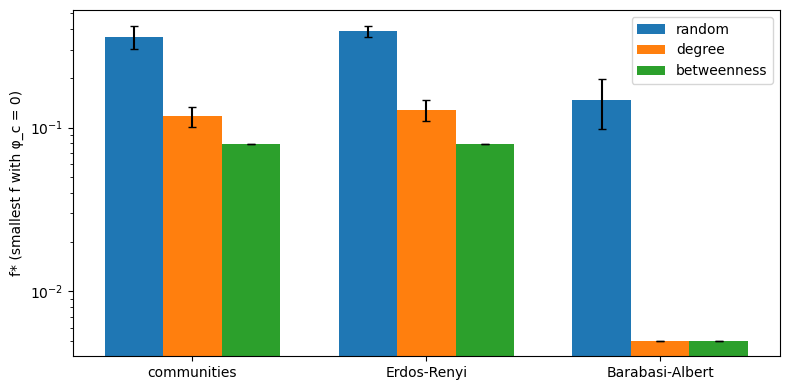

In [8]:
# critical budget, one group of bars per network
fig, ax = plt.subplots(figsize=(8, 4))
larghezza = 0.25
x = np.arange(len(grafi))
for n, protocollo in enumerate(protocolli):
    t = [sintesi_45.loc[(nome, protocollo)] for nome in grafi]
    ax.bar(x + (n - 1) * larghezza, [r["mean"] for r in t], larghezza, yerr=[r["std"] for r in t],
           capsize=3, label=protocollo)
ax.set_xticks(x, list(grafi))
ax.set_ylabel("f* (smallest f with φ_c = 0)")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.show()


**Comment on section 1.2.** The critical budget is largest for random screening, smaller with degree and smallest
with betweenness, on all the three networks (mean over 10 draws):

| `f*` | random | degree | betweenness |
|---|---|---|---|
| communities | 0.358 ± 0.058 | 0.118 ± 0.016 | 0.079 |
| Erdős-Rényi | 0.389 ± 0.031 | 0.128 ± 0.018 | 0.079 |
| Barabási-Albert | 0.148 ± 0.050 | 0.005 | 0.005 |

The results are consistent with section 1.1. The most striking one is Barabási-Albert: with degree or
betweenness 5 screened nodes out of 1000 are enough, about 30 times fewer than with random screening. Here the
protection is concentrated on the hubs, which are linked to each other, so very few of them already keep a
giant component. On Erdős-Rényi and communities the gain is smaller but still clear: betweenness needs about 5
times fewer nodes than random screening, and fewer than degree by more than twice the spread over the draws.

### 1.3 Total robustness

`(1 − f)(1 − φ_c)` is the expected fraction of **all** the nodes that can fail before the giant component disappears.

**Why.** The screened nodes, a fraction `f`, never fail. The other nodes, a fraction `1 − f` of the network, each
stay with probability `φ` and fail with probability `1 − φ`. The giant component survives as long as `φ > φ_c`,
so the most the non-screened nodes can take is a failure probability `1 − φ_c`. The expected fraction of failed
nodes at that point is the fraction of non-screened nodes times their failure probability:
`(1 − f)(1 − φ_c)`. It is the largest fraction of the whole network that can be lost while a giant component
still exists.

**Why we need it: the budget.** `φ_c` alone rewards screening many nodes: with a large `f` the threshold goes down
simply because a large part of the network cannot fail, and at `f = 1` it is 0 for any protocol. But every
screened node has a cost, and a screened node is also a node that is not allowed to fail. The total robustness
counts both: screening more nodes lowers `φ_c` (the second factor grows) but leaves fewer nodes that can fail
(the first factor shrinks). A protocol is really better only if it gains more in `1 − φ_c` than it spends in
`f`. The point is to screen few nodes, but the right ones.

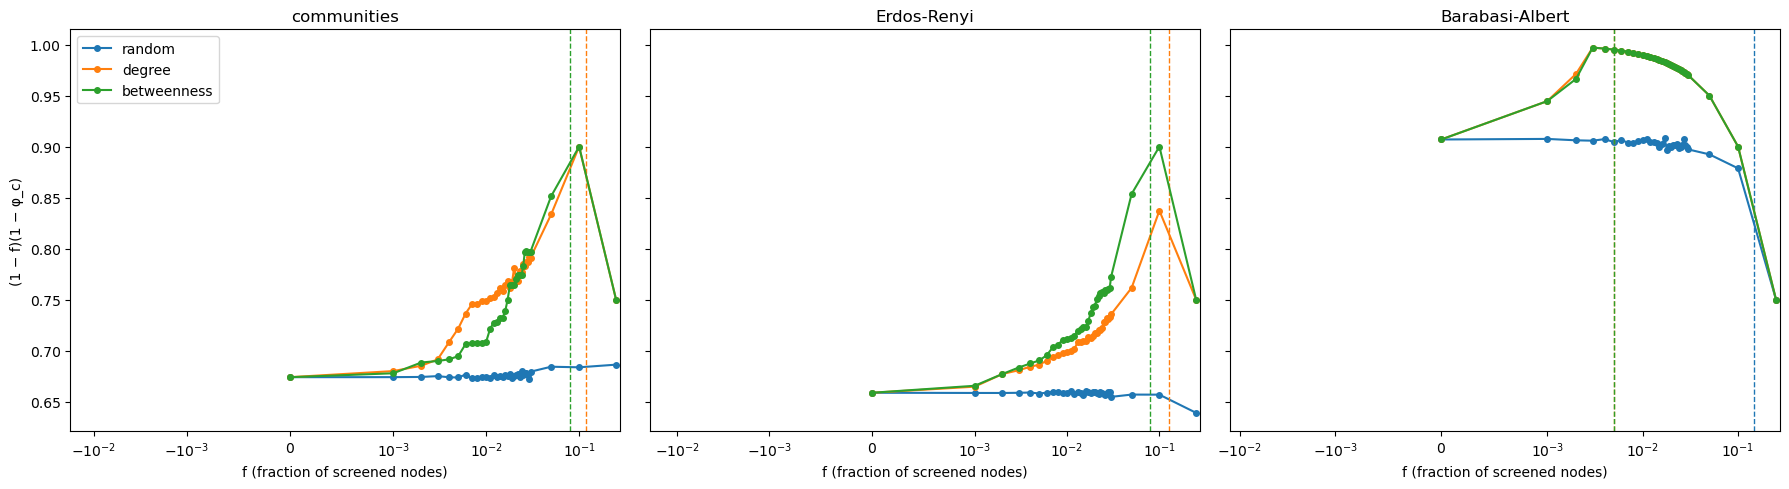

In [9]:
# dashed vertical lines: critical budget f* of each protocol (section 1.2)
fig, assi = plt.subplots(1, len(grafi), figsize=(18, 5), sharey=True)
for ax, nome in zip(assi, grafi):
    for protocollo in protocolli:
        t = sintesi_44.loc[(nome, protocollo)]
        robustezza = (1 - t.index.to_numpy()) * (1 - t["mean"])
        linea, = ax.plot(t.index, robustezza, "o-", ms=4, label=protocollo)
        # critical budget f* of section 1.2, same colour (off the axis when f* > the largest f of the grid)
        ax.axvline(sintesi_45.loc[(nome, protocollo), "mean"], color=linea.get_color(), ls="--", lw=1)
    ax.set_xscale("symlog", linthresh=0.001)
    ax.set_xlim(right=max(frazioni_44) * 1.1)
    ax.set_title(nome)
    ax.set_xlabel("f (fraction of screened nodes)")
assi[0].set_ylabel("(1 − f)(1 − φ_c)")
assi[0].legend()
plt.tight_layout()
plt.show()


**Comment on section 1.3.** A higher curve means a more robust network for the same budget. Here the value of
choosing *where* to screen is visible directly: degree and betweenness lie above random screening on all the
networks.

**Random screening is flat.** Each screened node lowers `φ_c`, but it is also a node removed from those that can
fail, and with random screening the two effects cancel exactly. From the annealed formula of notebook 03, section 4.3,
`(1 − f)(1 − φ_c) = (1 − f) − (1/λ_max − f) = 1 − 1/λ_max`: `f` drops out. The data follow this value for small
`f`: 0.674 on communities (1 − 1/λ_max = 0.674), 0.659 on Erdős-Rényi (0.659), 0.906-0.908 on Barabási-Albert
(0.907). For larger `f` on Barabási-Albert the curve goes down, where quenched and annealed separate (section 1.1).

**Degree and betweenness rise, then go down.** Here `φ_c` falls faster than `1 − f` shrinks, because the
protection goes to the nodes that hold the network together, so the product grows. Once `φ_c` reaches 0
(at the critical budget `f*`, dashed lines), all the non-screened nodes can fail and the robustness is just
`1 − f`: more screened nodes only remove nodes from the count, and the curve goes down linearly. The maximum is
therefore at `f*` or just before it, where `φ_c` is already almost 0: on Barabási-Albert 0.997 at `f = 0.003`
(`f* = 0.005`, 0.995); on communities 0.900 with both protocols and on Erdős-Rényi 0.900 with betweenness,
at `f = 0.1`, against 0.66-0.67 for random screening. The most efficient choice is to screen about `f*` nodes,
chosen well: few nodes, but the right ones.

### 1.4 Check against Monte Carlo

**Goal.** All the thresholds so far come from message passing: the bisection on `λ(M(φ)) = 1`. That rests on the
assumptions of message passing (independent failures, tree-like network). Here we estimate `φ_c` in an
independent way, by simulating the failures directly on the network with Monte Carlo, on the **same draw** of
screened nodes. Two questions: are the message passing thresholds close to the Monte Carlo ones, and do the
protocols come in the same order with both methods?

**How Monte Carlo finds the threshold: the susceptibility.** For each value of `φ` on a grid (below) we do 100
runs (20 per draw for random screening): in each run every non-screened node stays with probability `φ`, and we measure `S`, the
fraction of nodes in the largest component. Then we compute the susceptibility
`χ = (⟨S²⟩ − ⟨S⟩²)/⟨S⟩`, the variance of `S` over the runs divided by its mean (Radicchi, PRE 91, 010801 (2015),
arXiv:1412.3678, eqs. 2-3; same estimate as section 1.4 of notebook 02), and take as threshold the
`φ` where `χ` is largest. The reason is what happens to `S` in the three regimes:
- below the threshold every run breaks the network into small pieces, `S` is small in all the runs and changes little;
- above it there is always a giant component, of about the same size in every run: again small fluctuations;
- at the threshold the network is on the edge: in some runs the surviving nodes join into a large component, in
  others they do not, so `S` jumps from run to run and `χ` is largest.

In an infinite network these fluctuations diverge exactly at `φ_c` (percolation theory). On a finite network the
peak is finite and only an estimate: it falls a little above the true threshold and gets closer as `N` grows.

**What to expect.** Monte Carlo should lie somewhat above message passing, for two reasons: at `N = 1000` the peak
of `χ` is above the true threshold (section 1.6 of notebook 02: on Poisson networks with `N = 1000` the peak was at 0.41 against
the exact 1/3, about +0.08), and
on networks with loops `1/λ` is a lower bound of the threshold. **Grid**: step 0.005 from `φ_c MP − 0.1` to
`φ_c MP + 0.2` (shifted up, where the Monte Carlo peak is expected), step 0.05 elsewhere in `[0, 1]`
(`griglia_phi` in `mp.py`); a peak on the edge of the fine part is flagged. The grid gives the Monte Carlo value
only to ±0.005. When message passing gives `φ_c = 0`, or a value below 0.01, there is no transition the grid can
see and the peak of `χ` has no meaning: those cases are marked (`MP ≈ 0`) and left out of the scatter plot.

**What we look at.** `f` = 0, 1, 3, 10 and 30 screened nodes out of 1000, and 0.05, 0.10 as a reference; the
three protocols, the three networks; draws as in section 1.1, mean and standard deviation over the draws.
- The **table**: for each case `φ_c` from message passing (bisection) and from Monte Carlo (peak of `χ`), and the
  flag `MP ≈ 0`.
- **Plot 1**, Monte Carlo against message passing, one point per case: on the dashed diagonal the two agree, above
  it Monte Carlo is higher; the red line `MC = MP + 0.08` is the finite-size offset of notebook 02, section 1.6. We look at how far the points are from the diagonal and whether the distance is of
  the expected size.
- **Plot 2**, `φ_c` against `f`, one panel per network: message passing (solid) and Monte Carlo (dotted) for each
  protocol. We look at whether the two methods put the protocols in the same order and see the same drop of
  `φ_c` with `f`.

In [10]:
frazioni_47 = [0.0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.10]
num_runs_47 = 100          # one draw (degree, betweenness without ties)
num_runs_47_estr = 20      # per draw, when there are several draws (random)

ESEGUI_RUN_47 = False      # True: run again (a few minutes); False: read the results saved in soglie_mc.csv

if ESEGUI_RUN_47:
    righe = []
    for nome, g in grafi.items():
        G_mat, messaggi = matrice_G(g)
        str_mc = struttura_mc(g)             # arrays of the compiled Monte Carlo, once per network
        betw = nx.betweenness_centrality(g)
        for protocollo in protocolli:
            for frazione in frazioni_47:
                num_e = num_estrazioni(g, frazione, protocollo, betw)
                runs_e = num_runs_47 if num_e == 1 else num_runs_47_estr
                for e in range(num_e):
                    protetti = estrai_protetti(g, frazione, protocollo, rng, betw)
                    phi_c_mp = soglia_bisezione(g, G_mat, messaggi, protetti)

                    # Monte Carlo threshold: peak of the susceptibility on the same draw, fine grid above phi_c MP
                    phis_47 = griglia_phi(phi_c_mp + 0.05, larghezza=0.15, passo_fine=0.005)
                    runs = []
                    for phi in phis_47:
                        phi_n = phi_ibrido(g, protetti, phi)      # built once per phi, the same for all the runs
                        runs.append([mc_1run_veloce(g, phi_n, rng, str_mc) for _ in range(runs_e)])
                    runs = np.array(runs)
                    media = runs.mean(axis=1)
                    chi = runs.var(axis=1) / np.where(media > 0, media, np.nan)
                    picco = np.nanargmax(chi)
                    fine = np.diff(phis_47) < 0.01       # steps of the fine part
                    bordo = picco == 0 or picco == len(phis_47) - 1 or not (fine[picco - 1] and fine[picco])

                    righe.append({"network": nome, "protocol": protocollo, "f": frazione, "draw": e,
                                  "phi_c MP": phi_c_mp, "phi_c MC": phis_47[picco], "peak on edge": bordo})
    soglie_mc = pd.DataFrame(righe)
    soglie_mc.to_csv("risultati/04/soglie_mc.csv", index=False)     # saved, so that the run is not needed again
else:
    soglie_mc = pd.read_csv("risultati/04/soglie_mc.csv")

# mean and standard deviation over the draws (std empty with one draw)
sintesi_47 = soglie_mc.groupby(["network", "protocol", "f"], sort=False).agg(
    **{"phi_c MP": ("phi_c MP", "mean"), "std MP": ("phi_c MP", "std"),
       "phi_c MC": ("phi_c MC", "mean"), "std MC": ("phi_c MC", "std"),
       "draws": ("draw", "count"), "peaks on edge": ("peak on edge", "sum")}).reset_index()
sintesi_47["MP ≈ 0"] = sintesi_47["phi_c MP"] < 0.01     # below 0.01: no transition the MC grid can see
sintesi_47.round(3)

,network,protocol,f,phi_c MP,std MP,phi_c MC,std MC,draws,peaks on edge,MP ≈ 0
0,communities,random,0.000,0.326,NaN,0.396,NaN,1,0,False
1,communities,random,0.001,0.325,0.001,0.415,0.027,40,0,False
2,communities,random,0.003,0.324,0.002,0.418,0.027,20,0,False
3,communities,random,0.010,0.318,0.003,0.412,0.018,13,0,False
4,communities,random,0.030,0.303,0.007,0.390,0.030,11,0,False
...,...,...,...,...,...,...,...,...,...,...
58,Barabasi-Albert,betweenness,0.003,0.000,NaN,0.125,NaN,1,0,True
59,Barabasi-Albert,betweenness,0.010,0.000,NaN,0.200,NaN,1,1,True
60,Barabasi-Albert,betweenness,0.030,0.000,NaN,0.170,NaN,1,0,True
61,Barabasi-Albert,betweenness,0.050,0.000,NaN,0.200,NaN,1,1,True


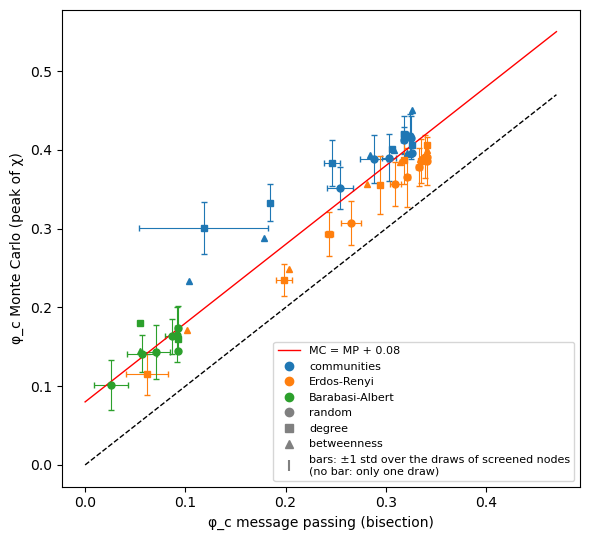

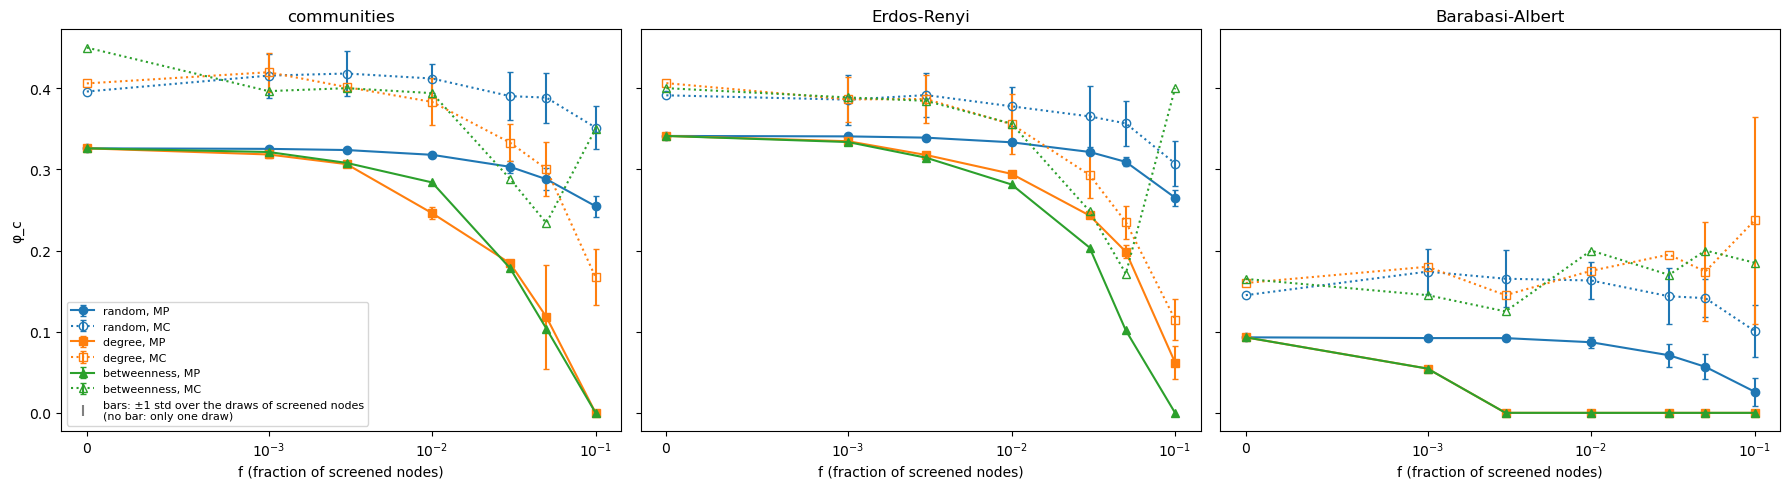

In [ ]:
# MC threshold against MP threshold (the cases with phi_c MP below 0.01 left out): on the dashed line they agree;
# error bars: standard deviation over the draws (random screening)
marker = {"random": "o", "degree": "s", "betweenness": "^"}
colore = dict(zip(grafi, ["tab:blue", "tab:orange", "tab:green"]))
validi = sintesi_47[~sintesi_47["MP ≈ 0"]]

fig, ax = plt.subplots(figsize=(6, 5.5))
for (nome, protocollo), t in validi.groupby(["network", "protocol"], sort=False):
    ax.errorbar(t["phi_c MP"], t["phi_c MC"], xerr=t["std MP"], yerr=t["std MC"], fmt=marker[protocollo],
                color=colore[nome], ms=5, capsize=2, lw=0.8)
lim = [0, max(validi["phi_c MC"].max(), validi["phi_c MP"].max()) + 0.02]
ax.plot(lim, lim, "k--", lw=1)
# finite-size offset of the peak of chi at N = 1000 (notebook 02, section 1.6: 0.41 against 1/3)
ax.plot(lim, [x + 0.08 for x in lim], "r-", lw=1, label="MC = MP + 0.08")
ax.set_xlabel("φ_c message passing (bisection)")
ax.set_ylabel("φ_c Monte Carlo (peak of χ)")
for nome in grafi:
    ax.plot([], [], "o", color=colore[nome], label=nome)
for protocollo in protocolli:
    ax.plot([], [], marker[protocollo], color="gray", label=protocollo)
ax.errorbar([], [], yerr=[], fmt="none", ecolor="gray", capsize=2,
            label="bars: ±1 std over the draws of screened nodes\n(no bar: only one draw)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# both thresholds against f, one panel per network: solid message passing, dotted Monte Carlo
fig, assi = plt.subplots(1, len(grafi), figsize=(18, 5), sharey=True)
for ax, nome in zip(assi, grafi):
    for n, protocollo in enumerate(protocolli):
        t = sintesi_47[(sintesi_47["network"] == nome) & (sintesi_47["protocol"] == protocollo)]
        ax.errorbar(t["f"], t["phi_c MP"], yerr=t["std MP"], fmt=marker[protocollo] + "-", color=f"C{n}",
                    capsize=2, label=f"{protocollo}, MP")
        ax.errorbar(t["f"], t["phi_c MC"], yerr=t["std MC"], fmt=marker[protocollo] + ":", color=f"C{n}",
                    mfc="none", capsize=2, label=f"{protocollo}, MC")
    ax.set_xscale("symlog", linthresh=0.001)      # linear below 0.001, logarithmic above
    ax.set_title(nome)
    ax.set_xlabel("f (fraction of screened nodes)")
assi[0].set_ylabel("φ_c")
assi[0].errorbar([], [], yerr=[], fmt="none", ecolor="gray", capsize=2,
                 label="bars: ±1 std over the draws of screened nodes\n(no bar: only one draw)")
assi[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**Comment on section 1.4.** As expected, Monte Carlo lies above message passing in all the cases (mean over the
draws). The gap is about constant in **absolute** terms, not in relative terms: the median of `φ_c MC − φ_c MP`
over the draws is 0.06-0.08 for every `f` (0.067, 0.083, 0.075, 0.060 for `f = 0, 0.01, 0.05, 0.10`), while the
median relative gap grows from 25% at `f = 0` to 43% at `f = 0.10`, because `φ_c MP` becomes small as `f` grows. That is why the points follow the red line `MC = MP + 0.08`
rather than a line of constant slope. This offset has the size measured in section 1.6 of notebook 02
for the peak of `χ` at `N = 1000` (0.41 against 1/3); on Erdős-Rényi with `f = 0` we find +0.050 to +0.065
(three independent Monte Carlo estimates on the same network, one per protocol).
Barabási-Albert has the lowest thresholds, communities and Erdős-Rényi the highest, as in section 1.1.

The two methods put the protocols in the same order wherever the comparison makes sense: on communities at
`f = 0.05`, 0.288 > 0.118 > 0.104 (random, degree, betweenness) with message passing and 0.39 > 0.30 > 0.23 with
Monte Carlo; on Erdős-Rényi 0.309 > 0.199 > 0.102 against 0.36 > 0.24 > 0.17. Where message passing gives
`φ_c ≈ 0` the Monte Carlo peak falls anywhere between 0.13 and 0.40: there is no transition and these points are
left out.

**Limits and note for the future.** The Monte Carlo threshold is itself biased at this size, so this section
cannot measure the error of message passing on `φ_c` precisely: it shows that the gap has the size expected from
the finite-size shift and that the ranking of the protocols is the same. One draw per case and a grid step of
0.01 add to the uncertainty. A sharper check would estimate the Monte Carlo threshold at larger `N` (as in
section 1.6 of notebook 02) or with a different estimator. The comparison of the whole curves
`S(φ)` in section 2 does not have this bias.

## 2. Curves S(φ) for each protocol

**Goal.** Section 1 reduces each case to one number, `φ_c`. Here we look at the whole curve `S(φ)`, the fraction
of nodes in the giant component as the non-screened nodes fail, for each network, protocol and fraction of
screened nodes. The curves show three things that `φ_c` alone does not:
- **how much** of the network survives at each `φ`, not only where the giant component disappears: screening can
  lift the whole curve or only move its starting point;
- the **limit `φ → 0`**: only the screened nodes are left and `S` is the giant component of their subgraph, so a
  curve that starts above zero is a network that never collapses (`φ_c = 0`, notebook 03, section 4.2, and section 1.2);
- the **accuracy of message passing on the whole curve**. Here Monte Carlo measures `S` directly, as an average
  over runs, and not a threshold through the peak of `χ`, so it does not suffer from the finite-size shift of
  section 1.4: it is the cleaner check of message passing, as in notebook 01.

**How.** `f` = 0, 1, 3, 10 and 30 screened nodes out of 1000, and 0.05, 0.10 as a reference. Each draw of the
screened nodes (quenched) is kept fixed for all the values of `φ`; draws as in section 1.1. Grid of `φ`: step
0.01 within ±0.1 of `φ_c` (the mean over the draws, widened by their spread), step 0.05 elsewhere in `[0, 1]`.
On each draw: message passing (lines), Monte Carlo with 50 runs per value of `φ` (20 per draw when there are
several draws). Monte Carlo is shown as the mean with two error measures: **shaded band** = standard error of the
mean (std / √runs: how precisely we know the mean), **error bars** = ±1 standard deviation of the runs (how much
one realisation fluctuates; it grows near the threshold, as `χ` in section 1.4). With several draws both are
taken within the draws, and the variability between draws is left out for now. The grid of plots shows three values of `f` (0.001, 0.003, 0.03), means and bars only, and the vertical lines are `φ_c` from the bisection of notebook 03, section 4.3 (dotted); the band and the Monte Carlo threshold are in section 2.1. `f = 0` is the same for the
three protocols. `S` is divided by all the `N` nodes, screened ones included, so at `φ = 1` it is the largest
component of the intact network (0.93 on Erdős-Rényi, 0.94 on communities, 1 on Barabási-Albert).

**What we look at.**
- The **3 × 3 grid of plots** (rows: protocols, columns: networks), one colour per `f`: whether the curves leave
  zero at the vertical line of their `φ_c`, how the curves move as `f` grows, and how this changes from random
  screening to degree and betweenness.
- The **RMS table**, message passing against Monte Carlo for each network, protocol and `f`. On the non-uniform
  grid the plain mean over the points would weigh the region around `φ_c` more, so the RMS is the integral form
  `sqrt(∫ (S_MP − S_MC)² dφ)` (trapezoidal rule, `scarto_quadratico_integrale`), close to the measure of
  sections 4.3 and 5.5 of notebook 01 on a uniform grid: whether message passing stays as accurate with screening as without.

In [12]:
frazioni_5 = [0.0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.10]
num_runs_5 = 50            # one draw
num_runs_5_estr = 20       # per draw, when there are several draws (random)

ESEGUI_RUN_5 = False      # True: run again (a few minutes); False: read the results saved in curve_protocolli.csv

if ESEGUI_RUN_5:
    righe = []
    for nome, g in grafi.items():
        G_mat, messaggi = matrice_G(g)
        struttura = struttura_mp(g)          # arrays of the compiled solvers, once per network
        str_mc = struttura_mc(g)
        betw = nx.betweenness_centrality(g)
        for protocollo in protocolli:
            for frazione in frazioni_5:
                num_e = num_estrazioni(g, frazione, protocollo, betw)
                runs_e = num_runs_5 if num_e == 1 else num_runs_5_estr

                # first all the draws and their phi_c (cheap), then one common grid for the case
                estrazioni = [estrai_protetti(g, frazione, protocollo, rng, betw) for _ in range(num_e)]
                soglie = [soglia_bisezione(g, G_mat, messaggi, p) for p in estrazioni]
                phis_5 = griglia_phi(np.mean(soglie), larghezza=0.1 + (max(soglie) - min(soglie)) / 2)

                for e, (protetti, phi_c) in enumerate(zip(estrazioni, soglie)):
                    # phi from high to low: each solve starts from the messages of the previous, higher phi
                    # (warm start). They lie above the new fixed point, so the iteration comes down to it
                    # and cannot stop at t = 0 above the threshold (as it would going from low to high).
                    t_prec = None
                    for phi in phis_5[::-1]:
                        phi_n = phi_ibrido(g, protetti, phi)
                        S_mp, _, t_prec, _, _ = message_passing_veloce(g, phi_n, t0=t_prec, struttura=struttura)
                        runs = [mc_1run_veloce(g, phi_n, rng, str_mc) for _ in range(runs_e)]
                        righe.append({"network": nome, "protocol": protocollo, "f": frazione, "draw": e, "phi": phi,
                                      "S MP": S_mp, "S MC": np.mean(runs),
                                      "S MC std": np.std(runs), "runs": runs_e, "phi_c": phi_c})
    curve_prot = pd.DataFrame(righe).sort_values(["network", "protocol", "f", "draw", "phi"], kind="stable")
    curve_prot.to_csv("risultati/04/curve_protocolli.csv", index=False)     # saved, so that the run is not needed again
else:
    curve_prot = pd.read_csv("risultati/04/curve_protocolli.csv")

# one curve per case: mean over the draws; std pooled within the draws; standard error over all the runs
curve_5 = curve_prot.groupby(["network", "protocol", "f", "phi"], sort=False).apply(
    lambda t: pd.Series({"S MP": t["S MP"].mean(), "S MC": t["S MC"].mean(),
                         "std": np.sqrt(np.mean(t["S MC std"] ** 2)),
                         "sem": np.sqrt(np.mean(t["S MC std"] ** 2)) / np.sqrt(t["runs"].sum()),
                         "phi_c": t["phi_c"].mean()}), include_groups=False).reset_index()

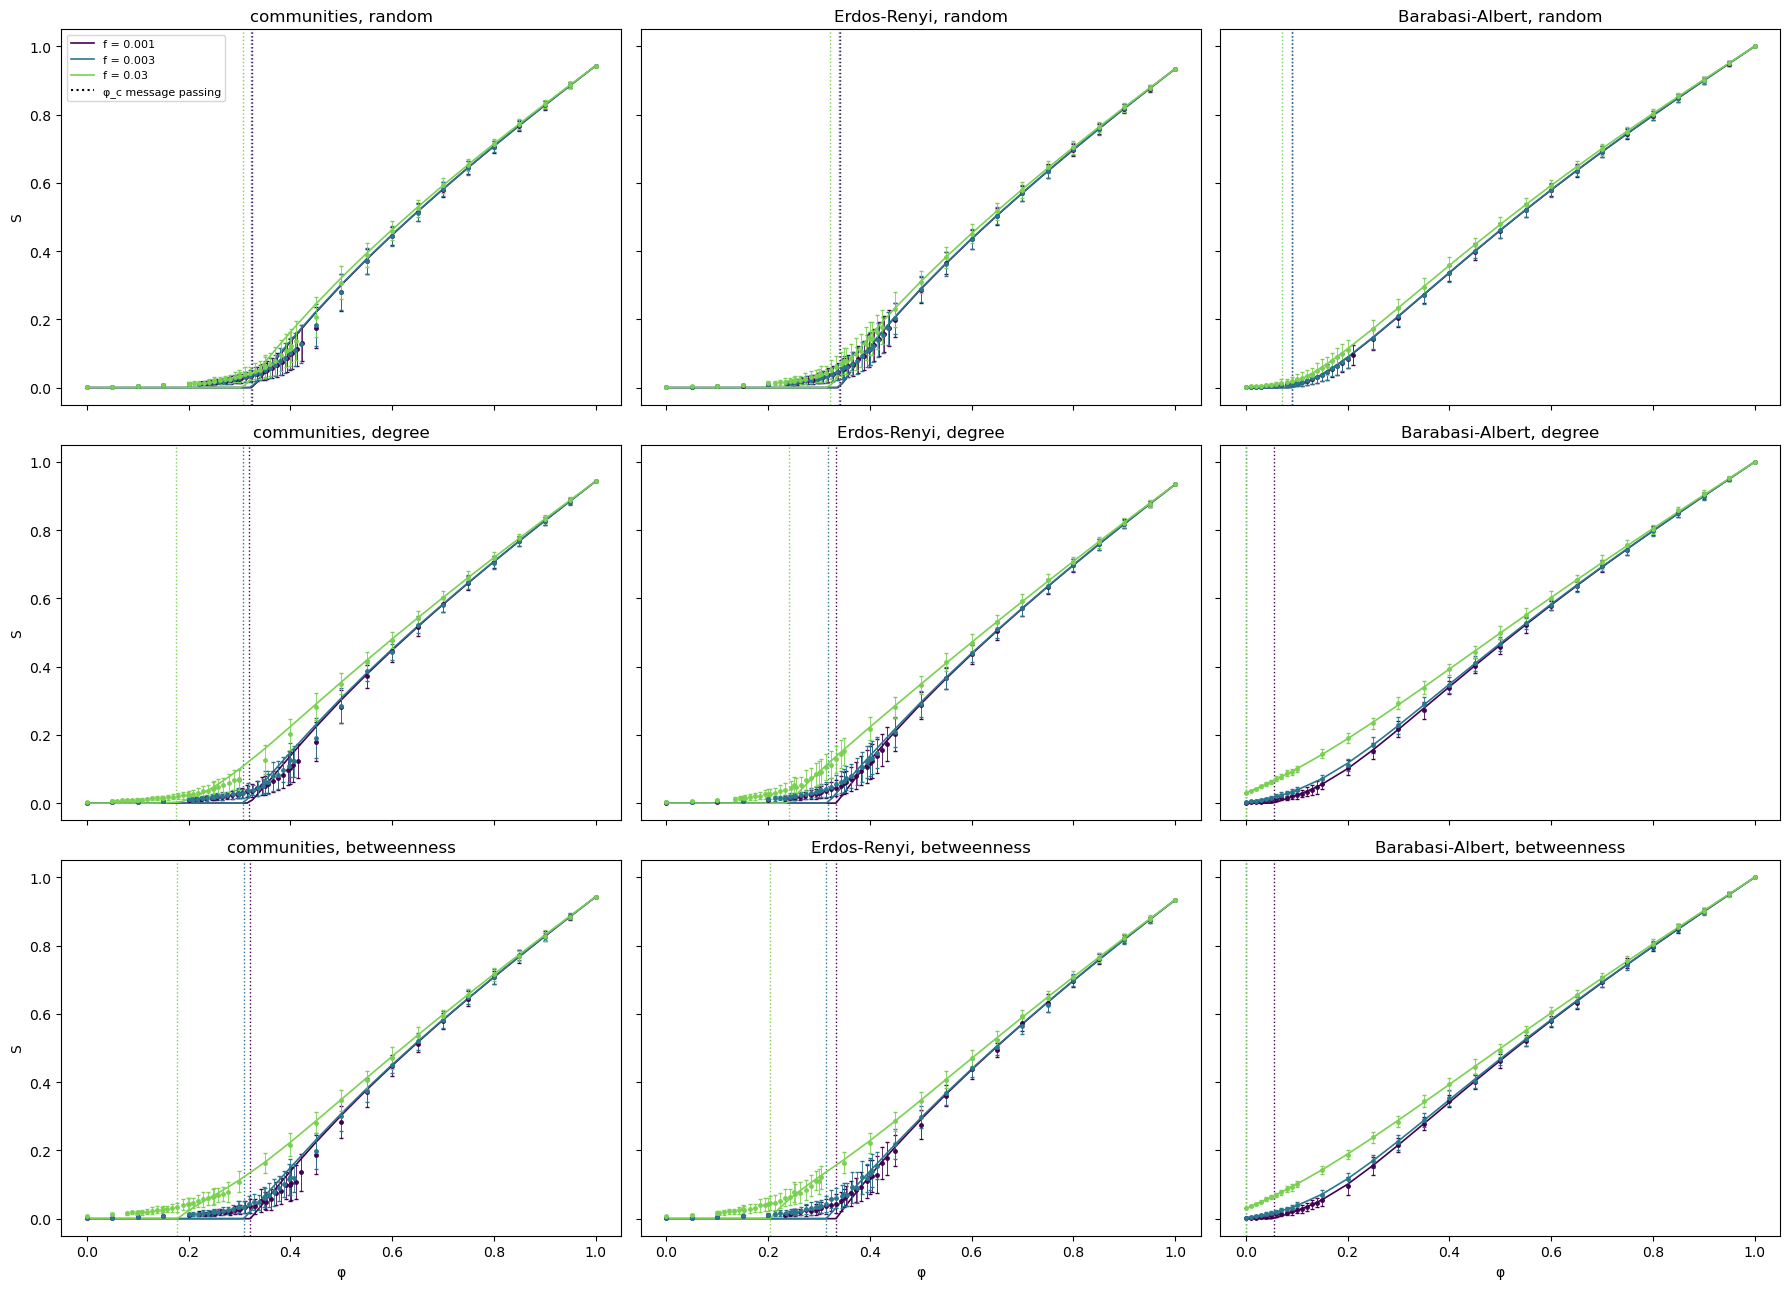

In [ ]:
# one row per protocol, one column per network, one colour per f: three values of f, the others are in curve_5
# line: message passing; dots: Monte Carlo mean, bars = ±1 std of the runs; vertical dotted lines: phi_c message passing
frazioni_grafico = [0.001, 0.003, 0.03]
colori = plt.cm.viridis(np.linspace(0, 0.8, len(frazioni_grafico)))
fig, assi = plt.subplots(len(protocolli), len(grafi), figsize=(18, 13), sharex=True, sharey=True)
for r, protocollo in enumerate(protocolli):
    for col, nome in enumerate(grafi):
        ax = assi[r, col]
        for frazione, colore in zip(frazioni_grafico, colori):
            t = curve_5[(curve_5["network"] == nome) & (curve_5["protocol"] == protocollo) & (curve_5["f"] == frazione)]
            ax.plot(t["phi"], t["S MP"], "-", color=colore, lw=1.2, label=f"f = {frazione}")
            ax.errorbar(t["phi"], t["S MC"], yerr=t["std"], fmt="o", color=colore, ms=2.5, capsize=1.5, lw=0.6)
            ax.axvline(t["phi_c"].iloc[0], color=colore, ls=":", lw=1)
        ax.set_title(f"{nome}, {protocollo}")
    assi[r, 0].set_ylabel("S")
for ax in assi[-1]:
    ax.set_xlabel("φ")
assi[0, 0].plot([], [], "k:", label="φ_c message passing")
assi[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [14]:
# RMS deviation between message passing and Monte Carlo (integral form, non-uniform grid):
# one row per (network, protocol), one column per f
rms_5 = curve_5.groupby(["network", "protocol", "f"], sort=False).apply(
    lambda t: scarto_quadratico_integrale(t["phi"], t["S MP"], t["S MC"]), include_groups=False)
rms_5.unstack("f").round(4)

f                             0.000   0.001   0.003   0.010   0.030   0.050  \
network         protocol                                                      
Barabasi-Albert betweenness  0.0035  0.0029  0.0024  0.0020  0.0022  0.0024   
                degree       0.0036  0.0030  0.0019  0.0019  0.0021  0.0012   
                random       0.0036  0.0029  0.0028  0.0027  0.0028  0.0029   
Erdos-Renyi     betweenness  0.0120  0.0120  0.0115  0.0113  0.0120  0.0114   
                degree       0.0124  0.0112  0.0110  0.0106  0.0106  0.0103   
                random       0.0121  0.0115  0.0115  0.0116  0.0119  0.0121   
communities     betweenness  0.0160  0.0155  0.0144  0.0136  0.0104  0.0111   
                degree       0.0151  0.0157  0.0151  0.0135  0.0124  0.0114   
                random       0.0163  0.0163  0.0157  0.0167  0.0162  0.0158   

f                             0.100  
network         protocol             
Barabasi-Albert betweenness  0.0020  
                degree       0.0006  
                random       0.0028  
Erdos-Renyi     betweenness  0.0015  
                degree       0.0095  
                random       0.0119  
communities     betweenness  0.0027  
                degree       0.0096  
                random       0.0166

#### Comment on section 2

**Random.** Screening more nodes at random lowers `φ_c` a little (communities from 0.326 to 0.25, Erdős-Rényi
from 0.341 to 0.27 at `f = 0.1`, mean over the draws), and the curves change little: at `φ = 0.25` the giant component is still absent.
Barabási-Albert is already very robust to random failures (`φ_c = 0.093` with no screening): this is the robust
side of its robust-yet-fragile behaviour. The fragile side is the vulnerability to attacks on the hubs, which are
not simulated here. In some draws random screening on Barabási-Albert reaches `φ_c = 0` (one draw out of 11 at
`f = 0.05`, two out of 10 at `f = 0.1`), lucky draws: the means over the draws in section 1.1 are 0.061 and 0.024.

**Degree.** The curves rise and the threshold moves to the left on all the networks. Barabási-Albert gains the most:
`φ_c = 0` already at `f = 0.01`, and at `φ = 0.25` `S` goes from 0.145 to 0.315 at `f = 0.1`. Screening by degree
protects exactly the hubs whose loss makes this network fragile. On communities and Erdős-Rényi, at `φ = 0.25`, `S`
goes from 0 to about 0.19-0.20 at `f = 0.1`.

**Betweenness.** All the networks gain, and at `f = 0.1` none of them has a threshold any more (`φ_c = 0`): the curves
start above zero at `φ = 0`. On Barabási-Albert degree and betweenness give the same curves.

**Message passing against Monte Carlo.** The RMS deviation stays between 0.001 and 0.017 in all the cases, the same
order as in notebook 01 without screening (0.013 on Erdős-Rényi, 0.004 on Barabási-Albert): message passing is as
accurate with screening as without. Here Monte Carlo measures `S` directly, so the gaps are not the shift of the
peak of `χ` of section 1.4. They are close to the threshold: on Erdős-Rényi Monte Carlo gives small non-zero values
where message passing gives 0 (the finite-size effect of notebook 01); on communities message passing is above
Monte Carlo by about 0.04-0.05 just above the threshold (our reading, not checked: each community has only 250
nodes, far from the infinite network message passing assumes).

### 2.1 Thresholds of message passing and Monte Carlo on the curves

The curves `S(φ)` of section 2, one grid of plots for each `f`, with the two thresholds drawn on them: `φ_c` of message
passing (bisection, dotted) and of Monte Carlo (peak of `χ`, section 1.4, dashed). Dark band: standard error of the
Monte Carlo mean; bars: ±1 std of the runs. Message passing is deterministic on a given draw and has no band. Axis cut
at `φ = 0.7`. Monte Carlo line not drawn where `φ_c MP ≈ 0`, as in section 1.4.

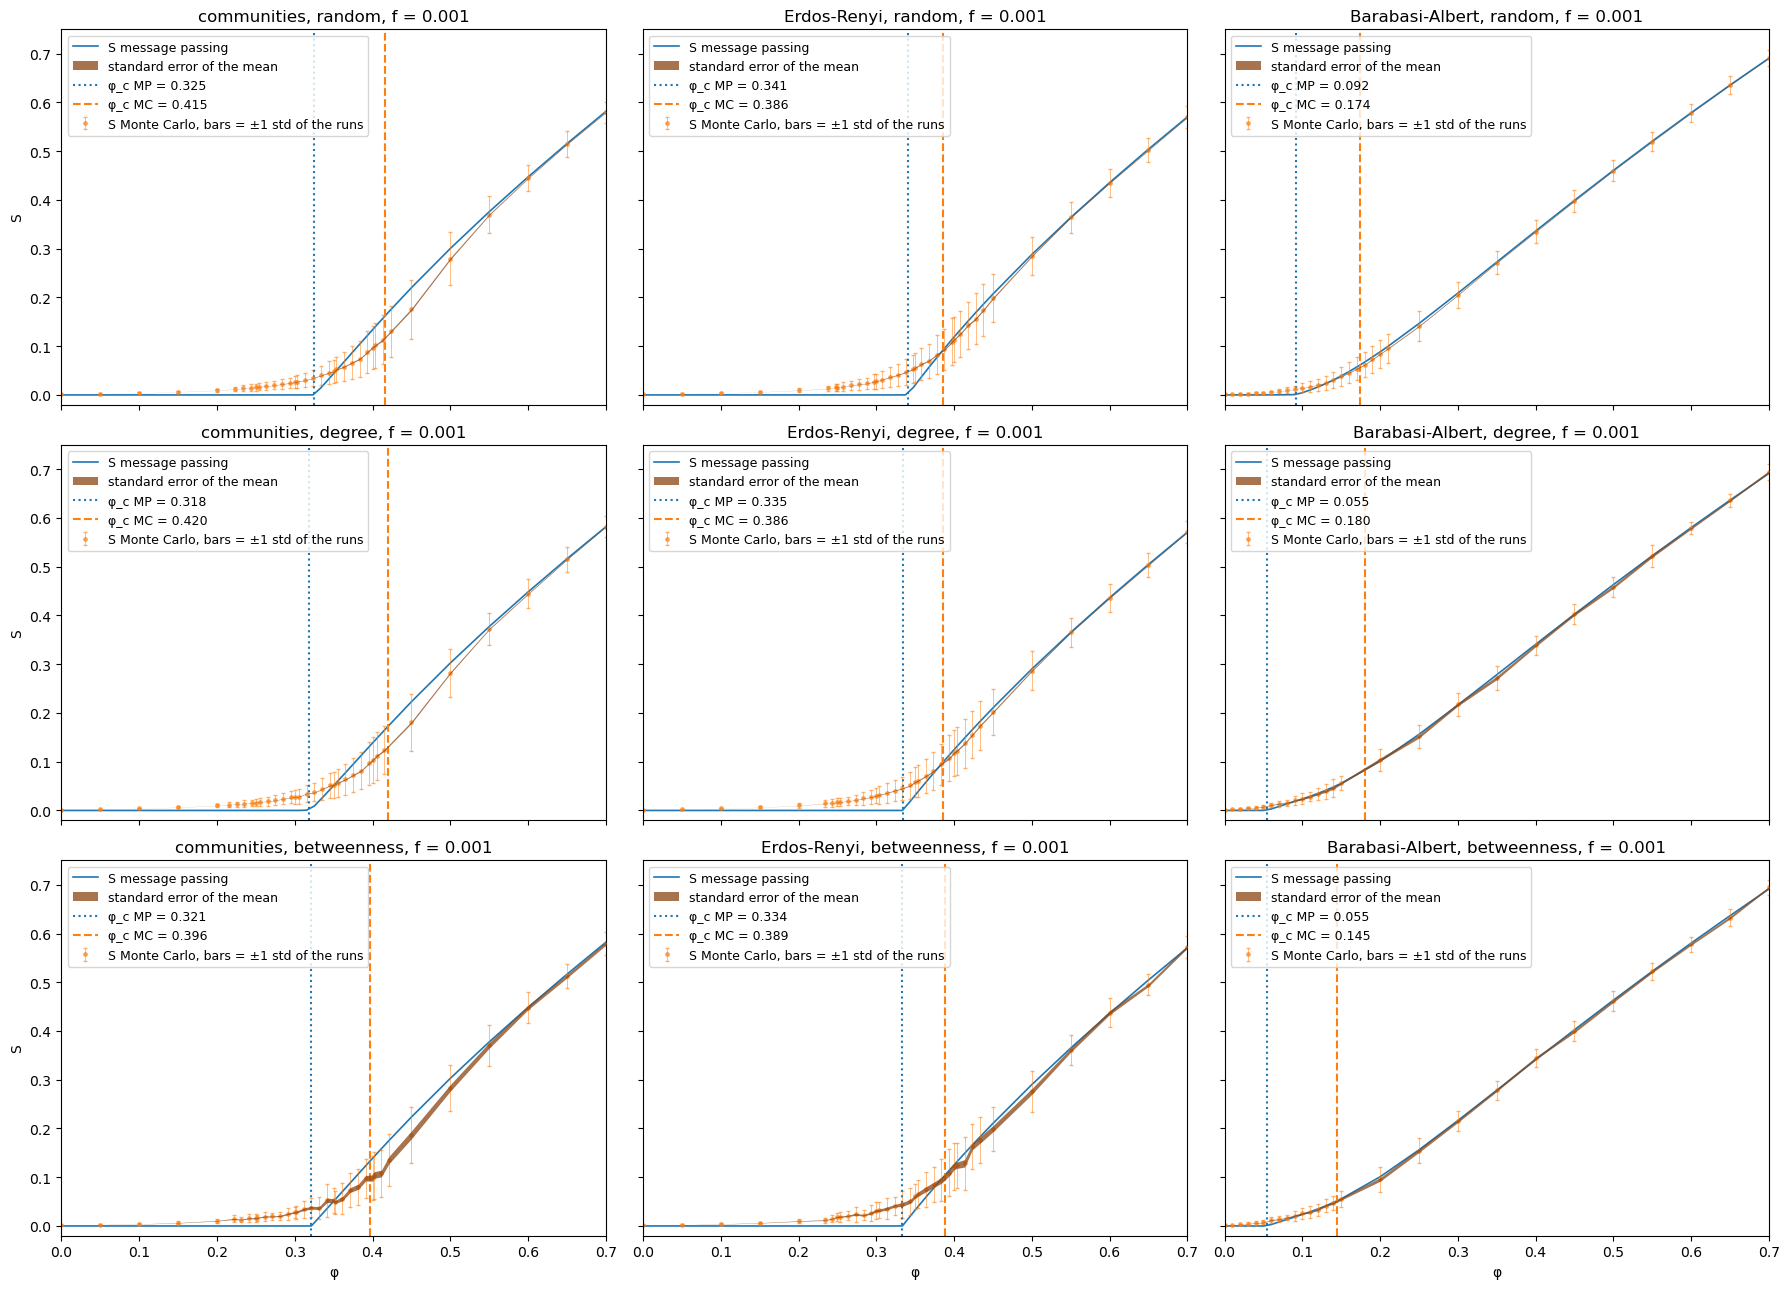

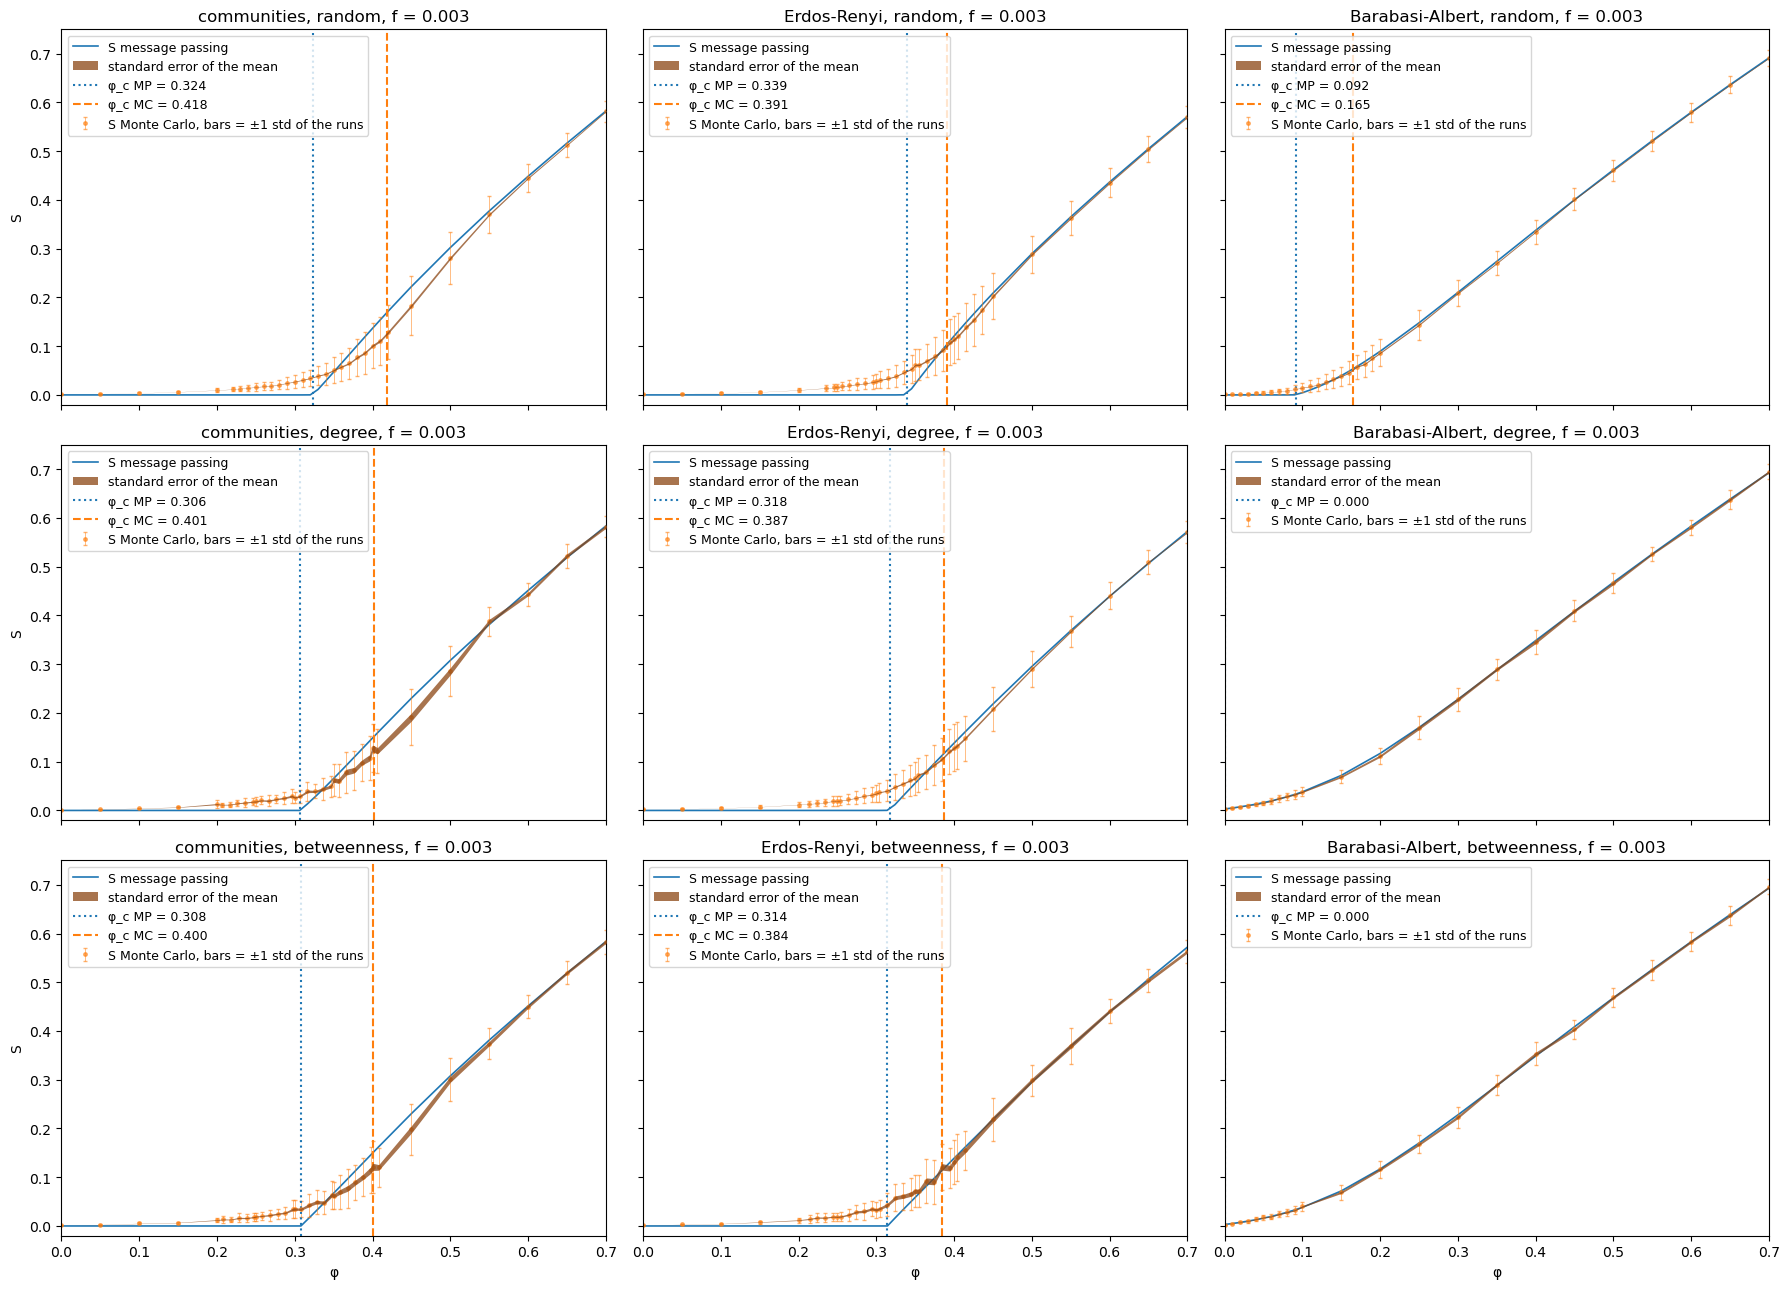

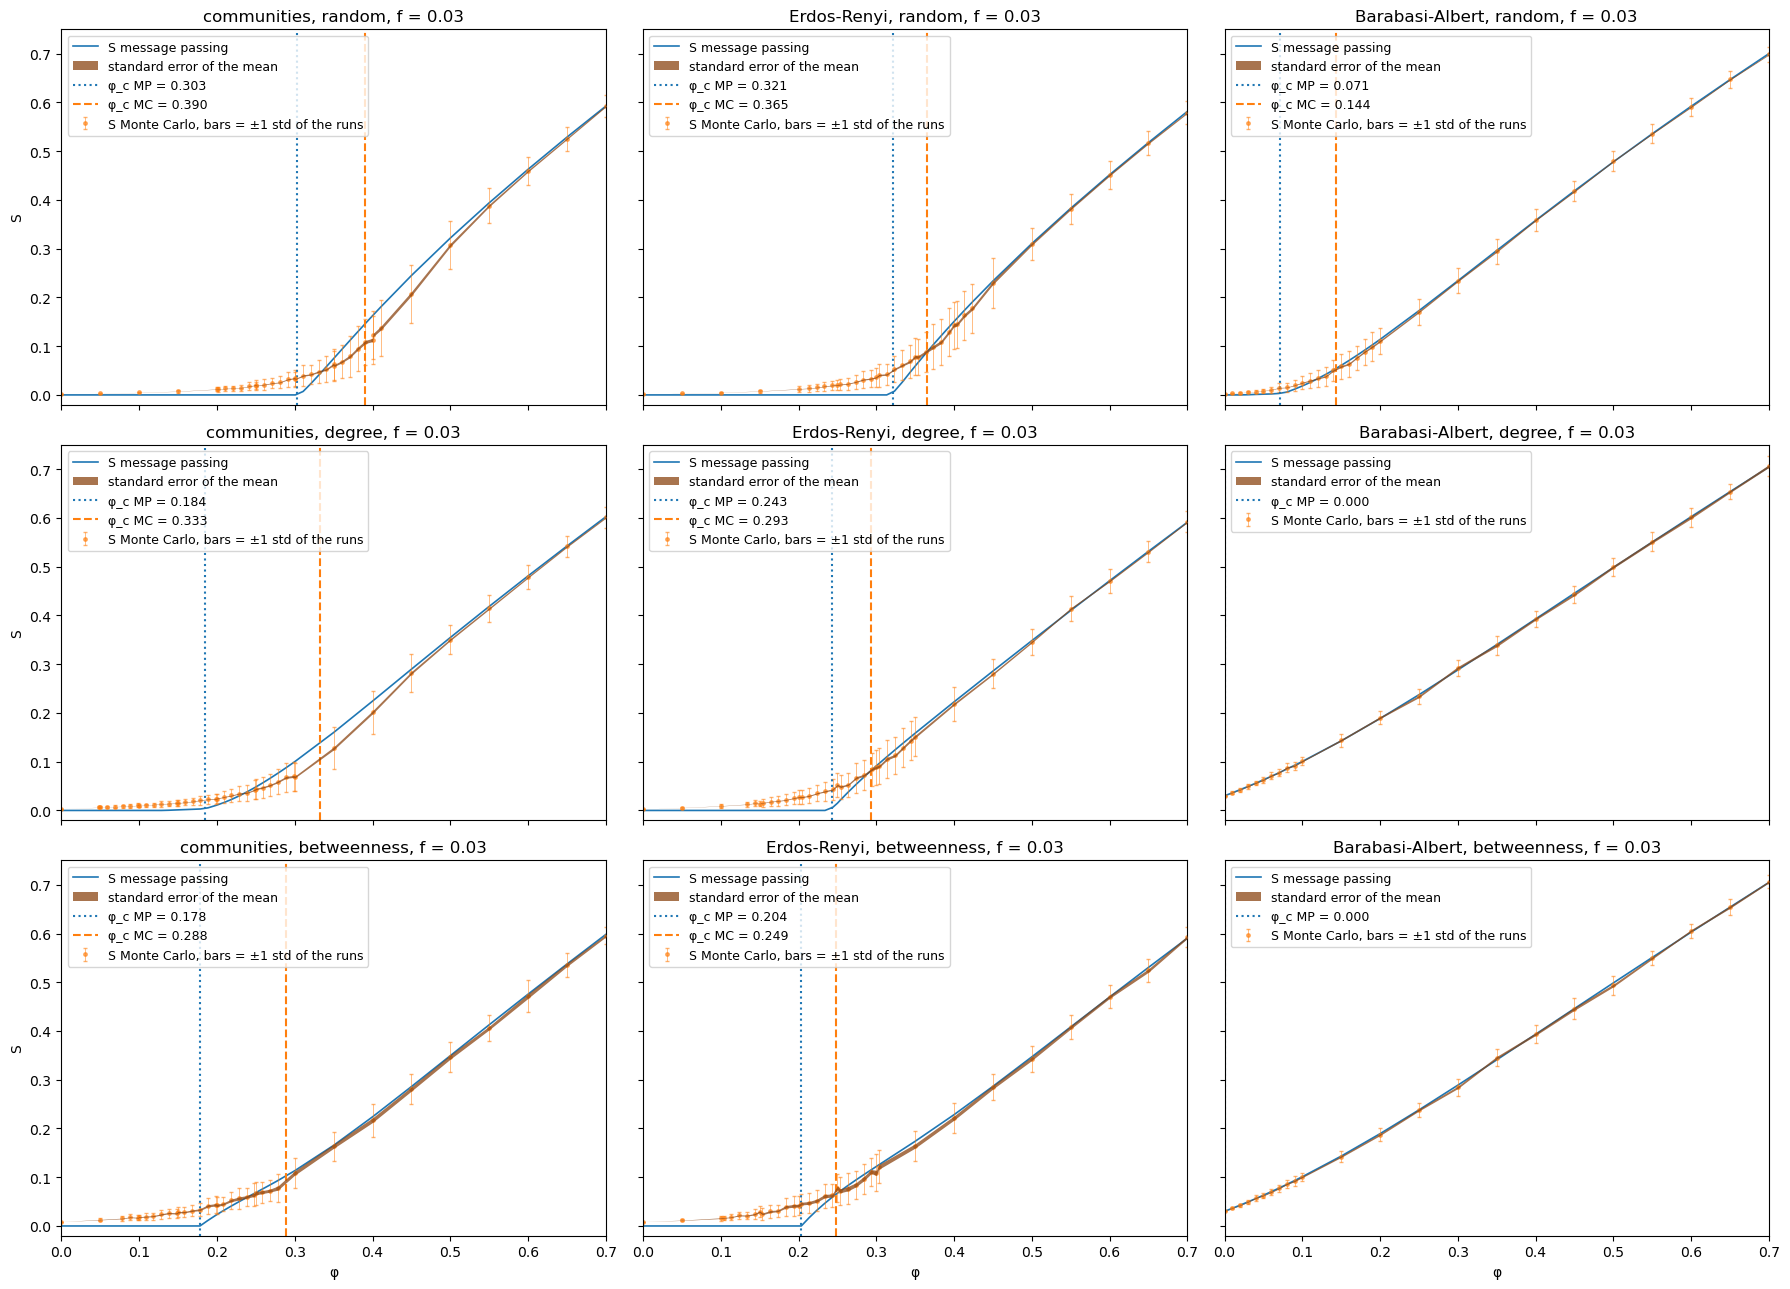

In [ ]:
for f_fissa in [0.001, 0.003, 0.03]:      # values of both frazioni_5 and frazioni_47
    fig, assi = plt.subplots(len(protocolli), len(grafi), figsize=(18, 13), sharex=True, sharey=True)
    for r, protocollo in enumerate(protocolli):
        for col, nome in enumerate(grafi):
            ax = assi[r, col]
            t = curve_5[(curve_5["network"] == nome) & (curve_5["protocol"] == protocollo) & (curve_5["f"] == f_fissa)]
            ax.plot(t["phi"], t["S MP"], "-", color="tab:blue", lw=1.2, label="S message passing")
            ax.errorbar(t["phi"], t["S MC"], yerr=t["std"], fmt="o", color="tab:orange", ms=2.5, capsize=1.5, lw=0.6,
                        alpha=0.6, label="S Monte Carlo, bars = ±1 std of the runs")
            ax.fill_between(t["phi"], t["S MC"] - t["sem"], t["S MC"] + t["sem"], color="saddlebrown", alpha=0.75, lw=0,
                            zorder=3, label="standard error of the mean")
            # both thresholds from section 1.4, computed on the same draws of the screened nodes
            mc = sintesi_47[(sintesi_47["network"] == nome) & (sintesi_47["protocol"] == protocollo)
                            & (sintesi_47["f"] == f_fissa)]
            phi_c_mp = mc["phi_c MP"].iloc[0]
            ax.axvline(phi_c_mp, color="tab:blue", ls=":", lw=1.5, label=f"φ_c MP = {phi_c_mp:.3f}")
            if not mc["MP ≈ 0"].iloc[0]:
                ax.axvline(mc["phi_c MC"].iloc[0], color="tab:orange", ls="--", lw=1.5,
                           label=f"φ_c MC = {mc['phi_c MC'].iloc[0]:.3f}")
            ax.set_xlim(0, 0.7)
            ax.set_title(f"{nome}, {protocollo}, f = {f_fissa}")
            ax.set_ylim(-0.02, 0.75)
            ax.legend(fontsize=9, loc="upper left")
        assi[r, 0].set_ylabel("S")
    for ax in assi[-1]:
        ax.set_xlabel("φ")
    plt.tight_layout()
    plt.show()

### 2.2 The network below and above φ_c

One realisation of the failures on Erdős-Rényi with no screening, at one `φ` below and one above the threshold, for
`N = 1000` and `N = 10000` (same mean degree). Each node has one random number and stays if it is below `φ`, so the nodes
alive on the left are also alive on the right. Same layout in the two panels. Red: largest component; blue: all the
other components; grey: failed nodes.

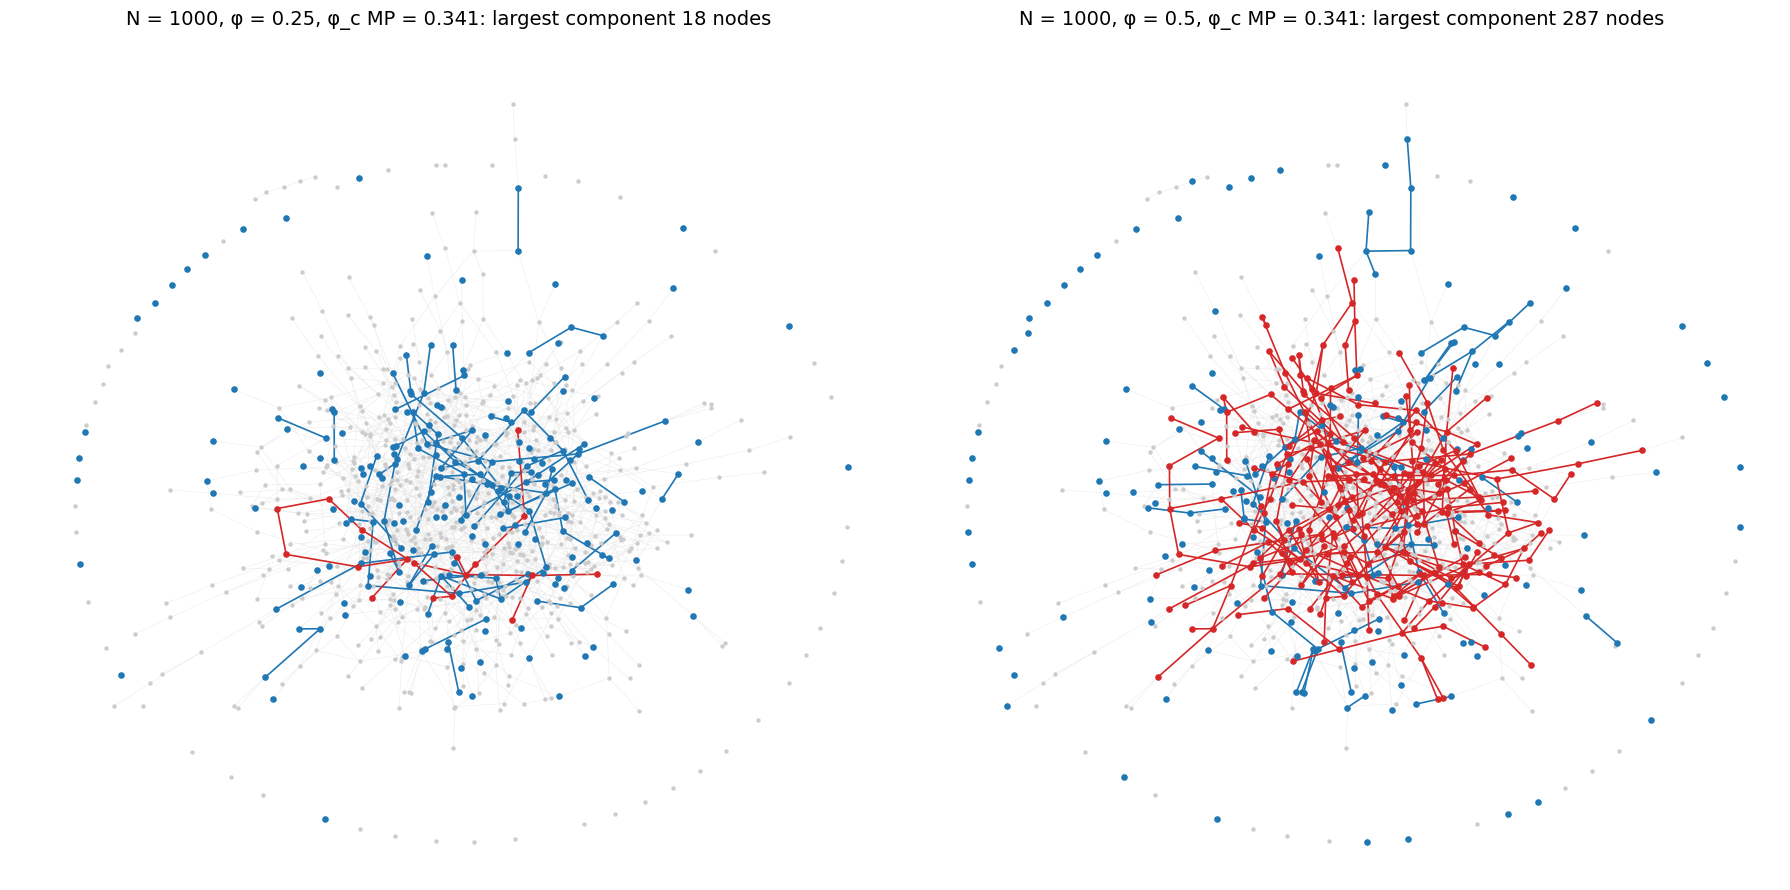

,N,phi,alive nodes,components,largest,largest / N,second,independent cycles in the largest
0,1000,0.25,257,150,18,0.018,15,0
1,1000,0.50,502,153,287,0.287,7,9


In [ ]:
def disegna_sotto_sopra(g, phi_sotto, phi_sopra, dim_nodo):
    """Draws one realisation of the failures on g at two values of phi, and returns a table of its components."""
    rng_vis = np.random.default_rng(7)         # its own generator: the rng of the other cells is not touched
    numeri = dict(zip(g.nodes, rng_vis.random(g.number_of_nodes())))
    pos = nx.spring_layout(g, seed=1, iterations=50)
    phi_c_vis = 1 / lambda_max(matrice_G(g)[0])
    N = g.number_of_nodes()

    fig, assi = plt.subplots(1, 2, figsize=(18, 9))
    righe = []
    for ax, phi in zip(assi, [phi_sotto, phi_sopra]):
        vivi = g.subgraph([n for n in g if numeri[n] < phi])
        componenti = sorted(nx.connected_components(vivi), key=len, reverse=True)
        grande = vivi.subgraph(componenti[0])
        altri = vivi.subgraph(set(vivi) - set(grande))

        nx.draw_networkx_edges(g, pos, ax=ax, edge_color="0.9", width=0.3)
        nx.draw_networkx_nodes(g, pos, nodelist=[n for n in g if n not in vivi], ax=ax, node_size=dim_nodo / 3, node_color="0.8")
        nx.draw_networkx_edges(altri, pos, ax=ax, edge_color="tab:blue", width=1.2)
        nx.draw_networkx_nodes(altri, pos, ax=ax, node_size=dim_nodo, node_color="tab:blue")
        nx.draw_networkx_edges(grande, pos, ax=ax, edge_color="tab:red", width=1.2)
        nx.draw_networkx_nodes(grande, pos, ax=ax, node_size=dim_nodo, node_color="tab:red")
        ax.set_title(f"N = {N}, φ = {phi}, φ_c MP = {phi_c_vis:.3f}: largest component {len(componenti[0])} nodes", fontsize=14)
        ax.set_axis_off()

        righe.append({"N": N, "phi": phi, "alive nodes": len(vivi), "components": len(componenti),
                      "largest": len(componenti[0]), "largest / N": len(componenti[0]) / N, "second": len(componenti[1]),
                      "independent cycles in the largest": grande.number_of_edges() - len(grande) + 1})
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(righe)

disegna_sotto_sopra(grafi["Erdos-Renyi"], 0.25, 0.5, dim_nodo=14)

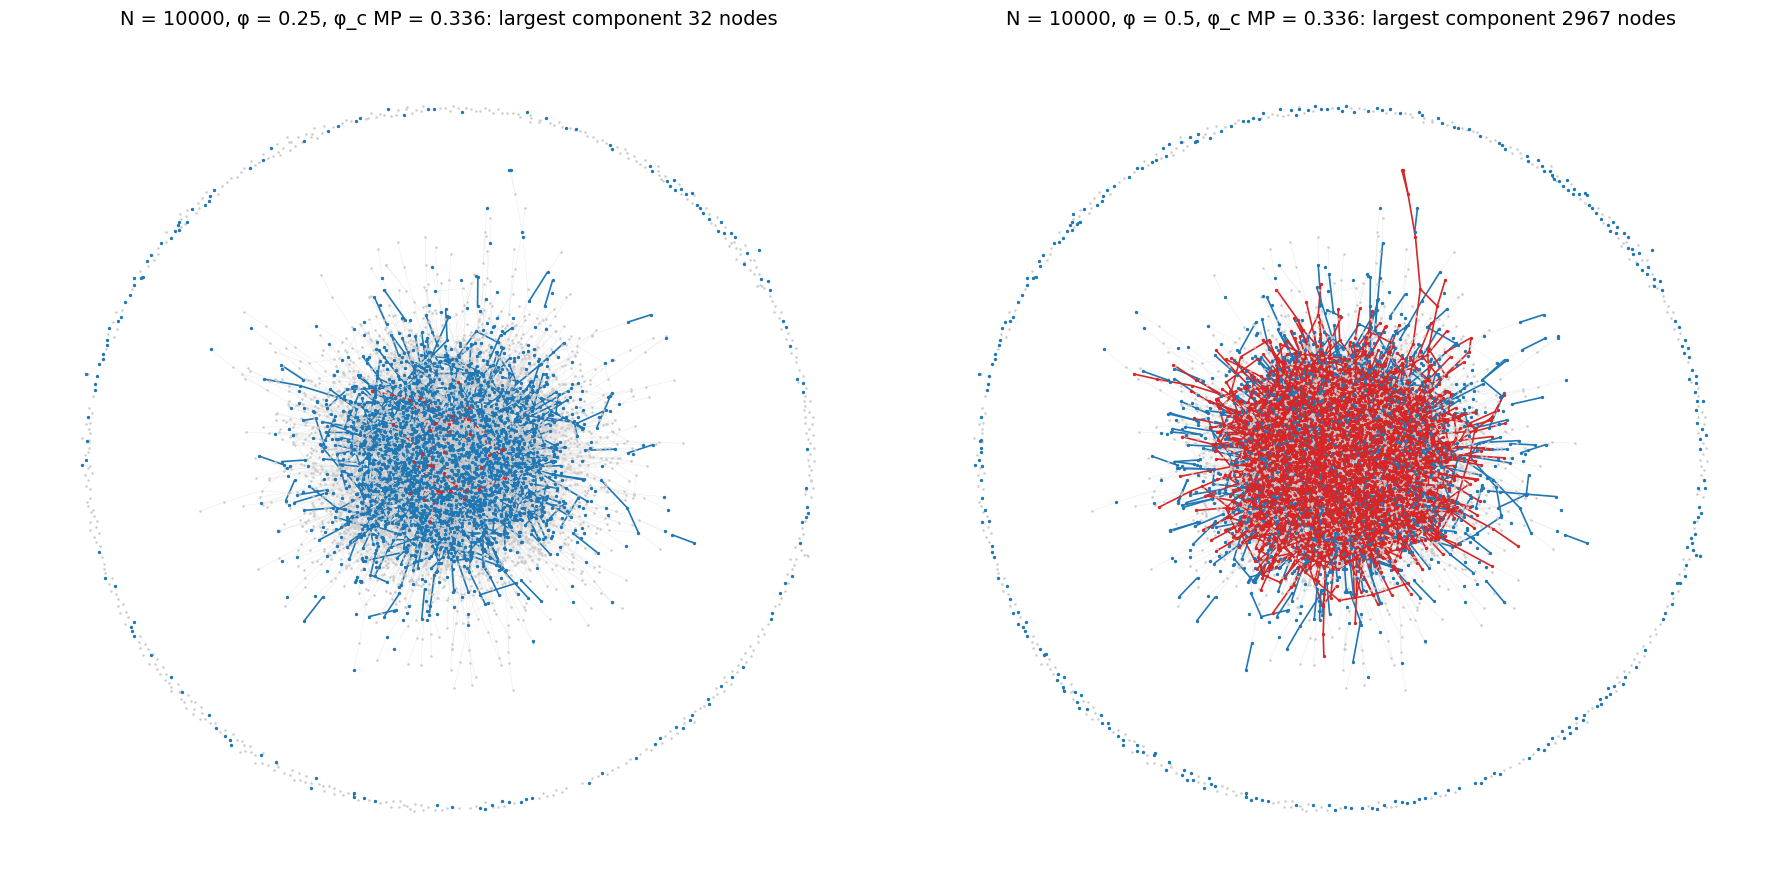

,N,phi,alive nodes,components,largest,largest / N,second,independent cycles in the largest
0,10000,0.25,2500,1557,32,0.0032,19,0
1,10000,0.50,4983,1416,2967,0.2967,23,172


In [ ]:
# same picture with ten times the nodes (about one minute, because of the layout)
g_10000 = nx.gnp_random_graph(10000, k_er / 9999, seed=1)
disegna_sotto_sopra(g_10000, 0.25, 0.5, dim_nodo=2)

## Conclusions

We implemented the hybrid `φ` in message passing: screened nodes at `φ = 1`, all the others at the same `φ`. The code
passes the checks against the cases we know: uniform `φ` (`λ(M) = φ λ_max`, `φ_c = 1/λ_max`), random screening
against the annealed theory `φ_eff`, and Monte Carlo on the same draws. With it we can apply different screening
protocols and measure their effect: the critical threshold `φ_c` (by bisection on `λ(M(φ)) = 1`), the critical
budget `f*` (the smallest fraction of screened nodes that keeps the giant component for every `φ`), the total
robustness `(1 − f)(1 − φ_c)` and the whole curves `S(φ)`.

On the three test networks (`N = 1000`), betweenness is the best protocol studied so far: it gives the lowest
`φ_c` and the smallest `f*`, and on Barabási-Albert it is as good as degree. Random screening gives no gain in total
robustness: what it gains in `φ_c` it spends in budget.

We are now ready to apply this to protein networks: choose a protocol and a fraction of screened nodes, and measure
`φ_c`, `f*`, the total robustness and the curves `S(φ)`.

**Limits.** The gap between message passing and Monte Carlo on `φ_c` has two parts. The first comes from the Monte
Carlo estimate: the peak of `χ` falls above the true threshold, by about +0.08 at `N = 1000`, less at larger `N`; on
networks with few triangles, like the three test networks here, it is almost all of the gap (section 1.4). The
second appears with triangles: message passing moves further from Monte Carlo as the clustering grows, and this
part does not shrink with `N` (notebook 02, section 1.6); the two add up. The direct comparison of the
curves `S(φ)` there points to message passing being less accurate on clustered networks, but this rests on the
assumption that triangles do not change the shift of the peak of `χ`, which is not checked yet. The protein
networks of notebook 06 have transitivity 0.24 to 0.40, so this matters for the next step.